# Road Accident Data Analysis, Visualization and Accident Severity Prediction Using Machine Learning
### Academic Capstone Data Science & Analytics Project (DAV)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

---

## 📌 Notebook Overview & Execution Architecture
This notebook presents an end-to-end data science and machine learning research workflow on highway traffic accident records. Every data manipulation step, missing value treatment, outlier assessment, feature engineering transformation, data wrangling operation, descriptive summary, visualization, and machine learning model evaluation is pre-computed and dynamically executable.

### Table of Contents:
1. **Import Libraries**
2. **Load Authentic Dataset (with Automatic Cloud Fallback)**
3. **Preliminary Structural Inspection**
4. **Data Cleaning — Missing-Value Detection**
5. **Data Cleaning — Missing-Value Imputation**
6. **Data Cleaning — Duplicate Identification & Removal**
7. **Data Cleaning — String Standardization & Casing Normalization**
8. **Data Cleaning — Outlier Detection (Interquartile Range - IQR)**
9. **Data Transformation (Derived Feature Engineering)**
10. **Data Wrangling Operations**
11. **Descriptive Statistics & Grouped Analysis**
12. **Exploratory Data Analysis (EDA) — Core Research Questions**
13. **Data Visualization Suite (8 Publication Charts)**
14. **Machine Learning Preprocessing Pipeline**
15. **Machine Learning Model 1 — Logistic Regression**
16. **Evaluation of Model 1 (Logistic Regression)**
17. **Machine Learning Model 2 — Random Forest Classifier**
18. **Evaluation of Model 2 (Random Forest Classifier)**
19. **Model Comparison & Performance Synthesis**
20. **Conclusion & Transportation Policy Recommendations**


## 1. Import Essential Libraries
We import Python scientific packages for data manipulation (Pandas, NumPy), charting (Matplotlib, Seaborn), and machine learning (Scikit-Learn).


In [1]:
import sys
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('All libraries successfully imported into environment.')


All libraries successfully imported into environment.


## 2. Load Authentic Dataset
We load the Road Traffic Accident (RTA) benchmark dataset. If executed in Google Colab, it automatically downloads the authentic CSV file directly into the Colab runtime.


In [2]:
# Load authentic road accident dataset
# Dual-mode loader: uses local file when running in project repo, or downloads directly from GitHub in Google Colab.
data_path = '../data/raw/road_accidents.csv'
if not os.path.exists(data_path):
    data_path = 'data/raw/road_accidents.csv'

if not os.path.exists(data_path):
    print('Running in Google Colab or fresh environment. Fetching authentic dataset from GitHub repository...')
    os.makedirs('data/raw', exist_ok=True)
    dataset_url = 'https://raw.githubusercontent.com/avikumart/Road-Traffic-Severity-Classification-Project/main/RTA%20Dataset.csv'
    urllib.request.urlretrieve(dataset_url, 'data/raw/road_accidents.csv')
    data_path = 'data/raw/road_accidents.csv'

df_raw = pd.read_csv(data_path)
print(f'Dataset successfully loaded! Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns.')


Dataset successfully loaded! Dimensions: 12,316 rows x 32 columns.


## 3. Preliminary Structural Inspection
We examine the shape, features, and preliminary records using `head()`, `tail()`, and `info()`.


In [3]:
print('--- FIRST 5 ROWS ---')
display(df_raw.head())

print('--- LAST 5 ROWS ---')
display(df_raw.tail())

print('--- DATASET INFO ---')
df_raw.info()


--- FIRST 5 ROWS ---


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,Area_accident_occured,Lanes_or_Medians,Road_allignment,Types_of_Junction,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Type_of_collision,Number_of_vehicles_involved,Number_of_casualties,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,No defect,Residential areas,NaN,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside-parked vehicles,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,No defect,Office areas,Undivided Two way,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,No defect,Recreational areas,other,NaN,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside objects,2,2,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,No defect,Office areas,other,Tangent road with mild grade and flat terrain,Y Shape,Earth roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,No defect,Industrial areas,other,Tangent road with flat terrain,Y Shape,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


--- LAST 5 ROWS ---


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,Area_accident_occured,Lanes_or_Medians,Road_allignment,Types_of_Junction,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Type_of_collision,Number_of_vehicles_involved,Number_of_casualties,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
12311,16:15:00,Wednesday,31-50,Male,NaN,Employee,2-5yr,Lorry (11?40Q),Owner,NaN,No defect,Outside rural areas,Undivided Two way,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,1,Going straight,na,na,na,na,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury
12312,18:00:00,Sunday,Unknown,Male,Elementary school,Employee,5-10yr,Automobile,Owner,NaN,No defect,Outside rural areas,Two-way (divided with broken lines road marking),Escarpments,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,1,Other,na,na,na,na,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury
12313,13:55:00,Sunday,Over 51,Male,Junior high school,Employee,5-10yr,Bajaj,Owner,2-5yrs,No defect,Outside rural areas,Two-way (divided with broken lines road marking),Tangent road with mountainous terrain and,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,1,1,Other,Driver or rider,Male,31-50,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Serious Injury
12314,13:55:00,Sunday,18-30,Female,Junior high school,Employee,Above 10yr,Lorry (41?100Q),Owner,2-5yrs,No defect,Office areas,Undivided Two way,Tangent road with mountainous terrain and,No junction,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,1,Other,na,na,na,na,Driver,Normal,Not a Pedestrian,Driving under the influence of drugs,Slight Injury
12315,13:55:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Other,Owner,2-5yrs,No defect,Outside rural areas,Undivided Two way,Tangent road with mountainous terrain and,O Shape,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,1,Stopping,Pedestrian,Female,5,3,Driver,Normal,Crossing from nearside - masked by parked or statioNot a Pedestrianry vehicle,Changing lane to the right,Slight Injury


--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         12316 non-null  object
 1   Day_of_week                  12316 non-null  object
 2   Age_band_of_driver           12316 non-null  object
 3   Sex_of_driver                12316 non-null  object
 4   Educational_level            11575 non-null  object
 5   Vehicle_driver_relation      11737 non-null  object
 6   Driving_experience           11487 non-null  object
 7   Type_of_vehicle              11366 non-null  object
 8   Owner_of_vehicle             11834 non-null  object
 9   Service_year_of_vehicle      8388 non-null   object
 10  Defect_of_vehicle            7889 non-null   object
 11  Area_accident_occured        12077 non-null  object
 12  Lanes_or_Medians             11931 non-null  object
 13  Road_allig

## 4. Data Cleaning — Missing-Value Detection
We audit missing data patterns across all attributes.


In [4]:
# Calculate missing value counts and percentages
null_counts = df_raw.isnull().sum()
null_pct = (null_counts / len(df_raw) * 100).round(2)
missing_summary = pd.DataFrame({
    'Missing_Count': null_counts,
    'Percentage (%)': null_pct
})
missing_cols = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print(f'Total features with missing values: {len(missing_cols)}')
display(missing_cols)


Total features with missing values: 16


,Missing_Count,Percentage (%)
Defect_of_vehicle,4427,35.95
Service_year_of_vehicle,3928,31.89
Work_of_casuality,3198,25.97
Fitness_of_casuality,2635,21.39
Type_of_vehicle,950,7.71
Types_of_Junction,887,7.20
Driving_experience,829,6.73
Educational_level,741,6.02
Vehicle_driver_relation,579,4.70
Owner_of_vehicle,482,3.91


## 5. Data Cleaning — Missing-Value Imputation
We impute missing values using median for numeric features (robust to skew) and mode/'Unknown' for categorical features.


In [5]:
# Apply systematic imputation
df_clean = df_raw.copy()

# 1. Numerical features: Median Imputation
num_cols = df_clean.select_dtypes(include=[np.number]).columns
for col in num_cols:
    if df_clean[col].isnull().sum() > 0:
        med_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(med_val)

# 2. Categorical features: Mode / 'Unknown' Imputation
cat_cols = df_clean.select_dtypes(include=['object']).columns
for col in cat_cols:
    if df_clean[col].isnull().sum() > 0:
        mode_val = df_clean[col].mode()[0] if not df_clean[col].mode().empty else 'Unknown'
        df_clean[col] = df_clean[col].fillna(mode_val)

print(f'Total missing values remaining after imputation: {df_clean.isnull().sum().sum()}')


Total missing values remaining after imputation: 0


## 6. Data Cleaning — Duplicate Identification & Removal
We inspect and purge duplicate collision entries to eliminate redundant bias.


In [6]:
dups_count = int(df_clean.duplicated().sum())
print(f'Duplicate records detected: {dups_count}')

df_clean = df_clean.drop_duplicates()
print(f'Cleaned dataset dimensions: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns.')


Duplicate records detected: 0
Cleaned dataset dimensions: 12,316 rows x 32 columns.


## 7. Data Cleaning — String Standardization & Casing Normalization
We strip extraneous whitespaces, resolve encoding glitches (e.g. `'41?100Q'` to `'41-100Q'`), and standardize target severity classifications.


In [7]:
# Normalize strings, strip extra whitespaces, and fix encoding defects
str_cols = df_clean.select_dtypes(include=['object']).columns
for c in str_cols:
    df_clean[c] = df_clean[c].astype(str).str.strip()

# Target normalization
df_clean['Accident_severity'] = df_clean['Accident_severity'].replace({
    'Fatal injury': 'Fatal Injury',
    'fatal injury': 'Fatal Injury',
    'Slight injury': 'Slight Injury',
    'Serious injury': 'Serious Injury'
})

# Clean character artifacts
df_clean['Type_of_vehicle'] = df_clean['Type_of_vehicle'].str.replace('?', '-', regex=False)
df_clean['Driving_experience'] = df_clean['Driving_experience'].replace({'unknown': 'Unknown'})

print('Accident Severity Class Distribution (Normalized):')
display(df_clean['Accident_severity'].value_counts())


Accident Severity Class Distribution (Normalized):


,count
Accident_severity,
Slight Injury,10415
Serious Injury,1743
Fatal Injury,158


## 8. Data Cleaning — Outlier Detection (Interquartile Range - IQR)
We calculate standard $1.5 \times \text{IQR}$ fences.
**Academic Justification for Retaining Outliers:** In traffic accident analysis, multi-vehicle pile-ups and severe casualty collisions represent genuine high-severity highway disasters. Removing them would discard the exact fatal and critical profiles our models must learn to predict.


In [8]:
def assess_iqr_outliers(series, feature_name):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    print(f'=== {feature_name} IQR Assessment ===')
    print(f'Q1 (25%): {q1:.1f} | Q3 (75%): {q3:.1f} | IQR: {iqr:.1f}')
    print(f'Calculated Normal Range: [{lower_bound:.2f}, {upper_bound:.2f}]')
    print(f'Identified Outliers: {len(outliers):,} records ({len(outliers)/len(series):.2%})
')

assess_iqr_outliers(df_clean['Number_of_vehicles_involved'], 'Number of Vehicles Involved')
assess_iqr_outliers(df_clean['Number_of_casualties'], 'Number of Casualties')


=== Number of Vehicles Involved IQR Assessment ===
Q1 (25%): 2.0 | Q3 (75%): 2.0 | IQR: 0.0
Calculated Normal Range: [2.00, 2.00]
Identified Outliers: 3,976 records (32.28%)

=== Number of Casualties IQR Assessment ===
Q1 (25%): 1.0 | Q3 (75%): 2.0 | IQR: 1.0
Calculated Normal Range: [-0.50, 3.50]
Identified Outliers: 720 records (5.85%)


## 9. Data Transformation (Derived Feature Engineering)
We extract temporal properties (`Hour`, `Minute`, `Time_of_day`, `Rush_hour`), calendar indicators (`Day_type`), and risk dimensions (`Collision_scale`, `Casualty_scale`).


In [9]:
# Feature Engineering Pipeline
time_dt = pd.to_datetime(df_clean['Time'].astype(str), format='%H:%M:%S', errors='coerce').dt
df_clean['Hour'] = time_dt.hour.fillna(12).astype(int)
df_clean['Minute'] = time_dt.minute.fillna(0).astype(int)

# 1. Time of Day
def get_time_of_day(hour):
    if 6 <= hour < 12: return 'Morning'
    elif 12 <= hour < 17: return 'Afternoon'
    elif 17 <= hour < 22: return 'Evening'
    else: return 'Night'

# 2. Rush Hour
def get_rush_hour(hour):
    return 'Rush Hour' if (7 <= hour <= 9) or (16 <= hour <= 19) else 'Non-Rush Hour'

# 3. Day Type
def get_day_type(day):
    return 'Weekend' if str(day).strip() in ['Saturday', 'Sunday'] else 'Weekday'

# 4. Operational Scales
def get_collision_scale(v):
    if v <= 1: return 'Single Vehicle'
    elif v == 2: return 'Two Vehicles'
    else: return 'Multi-Vehicle Pile-up'

def get_casualty_scale(c):
    if c <= 1: return 'Low Casualty (1)'
    elif c == 2: return 'Medium Casualty (2)'
    else: return 'High Casualty (3+)'

df_clean['Time_of_day'] = df_clean['Hour'].apply(get_time_of_day)
df_clean['Rush_hour'] = df_clean['Hour'].apply(get_rush_hour)
df_clean['Day_type'] = df_clean['Day_of_week'].apply(get_day_type)
df_clean['Collision_scale'] = df_clean['Number_of_vehicles_involved'].apply(get_collision_scale)
df_clean['Casualty_scale'] = df_clean['Number_of_casualties'].apply(get_casualty_scale)

print('Feature Engineering Completed. Transformed Attributes Sample:')
display(df_clean[['Time', 'Hour', 'Time_of_day', 'Rush_hour', 'Day_of_week', 'Day_type', 'Collision_scale', 'Casualty_scale']].head())


Feature Engineering Completed. Transformed Attributes Sample:


,Time,Hour,Time_of_day,Rush_hour,Day_of_week,Day_type,Collision_scale,Casualty_scale
0,17:02:00,17,Evening,Rush Hour,Monday,Weekday,Two Vehicles,Medium Casualty (2)
1,17:02:00,17,Evening,Rush Hour,Monday,Weekday,Two Vehicles,Medium Casualty (2)
2,17:02:00,17,Evening,Rush Hour,Monday,Weekday,Two Vehicles,Medium Casualty (2)
3,1:06:00,1,Night,Non-Rush Hour,Sunday,Weekend,Two Vehicles,Medium Casualty (2)
4,1:06:00,1,Night,Non-Rush Hour,Sunday,Weekend,Two Vehicles,Medium Casualty (2)


## 10. Data Wrangling Operations
We demonstrate essential Pandas data wrangling techniques: filtering, sorting, multi-aggregation, multi-dimensional pivot tables, and cross-tabulations.


In [10]:
# 1. Filtering high-casualty incidents (3+ casualties)
high_risk = df_clean[df_clean['Number_of_casualties'] >= 3]
print(f'1. Filtered High-Risk Incidents (3+ casualties): {len(high_risk):,} records')

# 2. Sorting by casualties and vehicles
print('2. Top 5 Most Severe Multi-Vehicle Collisions:')
display(df_clean.sort_values(by=['Number_of_casualties', 'Number_of_vehicles_involved'], ascending=False)[
    ['Time', 'Day_of_week', 'Weather_conditions', 'Number_of_vehicles_involved', 'Number_of_casualties', 'Accident_severity']
].head())

# 3. Multi-aggregation GroupBy
print('3. Casualty Metrics by Light Conditions:')
light_agg = df_clean.groupby('Light_conditions')['Number_of_casualties'].agg(['count', 'mean', 'median', 'std', 'max']).reset_index()
display(light_agg)

# 4. Multi-dimensional Pivot Table (Day of Week vs Time of Day)
pivot_day_time = pd.pivot_table(
    df_clean,
    index='Day_of_week',
    columns='Time_of_day',
    values='Number_of_casualties',
    aggfunc='count',
    fill_value=0
)
print('4. Multi-Dimensional Pivot Table (Day vs Time of Day):')
display(pivot_day_time)

# 5. Cross-tabulation (Weather vs Severity)
print('5. Cross-Tabulation: Weather Conditions vs Accident Severity:')
display(pd.crosstab(df_clean['Weather_conditions'], df_clean['Accident_severity'], margins=True))


1. Filtered High-Risk Incidents (3+ casualties): 1,629 records
2. Top 5 Most Severe Multi-Vehicle Collisions:


,Time,Day_of_week,Weather_conditions,Number_of_vehicles_involved,Number_of_casualties,Accident_severity
3692,17:35:00,Saturday,Normal,2,8,Slight Injury
3693,17:35:00,Saturday,Normal,2,8,Slight Injury
3694,17:35:00,Saturday,Normal,2,8,Slight Injury
3695,17:35:00,Saturday,Normal,2,8,Slight Injury
3696,17:35:00,Saturday,Normal,2,8,Slight Injury


3. Casualty Metrics by Light Conditions:


,Light_conditions,count,mean,median,std,max
0,Darkness - lights lit,3286,1.637553,1.0,1.076853,7
1,Darkness - lights unlit,40,1.200000,1.0,0.405096,2
2,Darkness - no lighting,192,1.817708,1.0,1.089262,5
3,Daylight,8798,1.510457,1.0,0.976741,8


4. Multi-Dimensional Pivot Table (Day vs Time of Day):


Time_of_day,Afternoon,Evening,Morning,Night
Day_of_week,,,,
Friday,598,667,532,244
Monday,596,474,480,131
Saturday,588,506,275,297
Sunday,489,436,275,267
Thursday,529,645,549,128
Tuesday,553,599,505,113
Wednesday,544,570,620,106


5. Cross-Tabulation: Weather Conditions vs Accident Severity:


Accident_severity,Fatal Injury,Serious Injury,Slight Injury,All
Weather_conditions,,,,
Cloudy,0,8,117,125
Fog or mist,0,1,9,10
Normal,135,1474,8454,10063
Other,0,28,268,296
Raining,23,158,1150,1331
Raining and Windy,0,2,38,40
Snow,0,5,56,61
Unknown,0,51,241,292
Windy,0,16,82,98


## 11. Descriptive Statistics & Grouped Analysis
We calculate standard statistical summaries (Mean, Median, Std, Quartiles) and multi-level grouped aggregations across accident severity.


In [11]:
# Summary Statistics for Numerical Attributes
print('=== NUMERICAL DESCRIPTIVE STATISTICS ===')
display(df_clean[['Number_of_vehicles_involved', 'Number_of_casualties', 'Hour']].describe().T)

# Grouped Statistics by Accident Severity
print('=== GROUPED METRICS BY ACCIDENT SEVERITY ===')
sev_summary = df_clean.groupby('Accident_severity').agg(
    Total_Accidents=('Accident_severity', 'count'),
    Avg_Casualties=('Number_of_casualties', 'mean'),
    Max_Casualties=('Number_of_casualties', 'max'),
    Total_Casualties=('Number_of_casualties', 'sum'),
    Avg_Vehicles=('Number_of_vehicles_involved', 'mean')
).reset_index()
display(sev_summary)


=== NUMERICAL DESCRIPTIVE STATISTICS ===


,count,mean,std,min,25%,50%,75%,max
Number_of_vehicles_involved,12316.0,2.040679,0.688790,1.0,2.0,2.0,2.0,7.0
Number_of_casualties,12316.0,1.548149,1.007179,1.0,1.0,1.0,2.0,8.0
Hour,12316.0,13.835823,5.202923,0.0,10.0,15.0,18.0,23.0


=== GROUPED METRICS BY ACCIDENT SEVERITY ===


,Accident_severity,Total_Accidents,Avg_Casualties,Max_Casualties,Total_Casualties,Avg_Vehicles
0,Fatal Injury,158,2.341772,5,370,1.797468
1,Serious Injury,1743,1.535284,6,2676,1.895009
2,Slight Injury,10415,1.538262,8,16021,2.068747


## 12. Exploratory Data Analysis (EDA) — Core Research Questions
We systematically answer all 11 core transportation safety research questions with empirical evidence.


In [12]:
# Systematically Answer All 11 Core Transportation Research Questions
print('=== EXPLORATORY DATA ANALYSIS (11 RESEARCH QUESTIONS) ===\n')

# Q1
print(f'1. Total Accidents: {len(df_clean):,}')

# Q2
sev_vc = df_clean['Accident_severity'].value_counts()
print(f'2. Most Frequent Severity: {sev_vc.index[0]} ({sev_vc.iloc[0]:,} incidents, {sev_vc.iloc[0]/len(df_clean):.1%})')

# Q3
w_vc = df_clean['Weather_conditions'].value_counts()
print(f'3. Weather with Highest Crashes: {w_vc.index[0]} ({w_vc.iloc[0]:,} incidents, {w_vc.iloc[0]/len(df_clean):.1%})')

# Q4
r_vc = df_clean['Road_surface_conditions'].value_counts()
print(f'4. Road Surface with Highest Crashes: {r_vc.index[0]} ({r_vc.iloc[0]:,} incidents, {r_vc.iloc[0]/len(df_clean):.1%})')

# Q5
d_vc = df_clean['Day_of_week'].value_counts()
print(f'5. Peak Day of the Week: {d_vc.index[0]} ({d_vc.iloc[0]:,} incidents, {d_vc.iloc[0]/len(df_clean):.1%})')

# Q6
h_vc = df_clean['Hour'].value_counts()
print(f'6. Peak Collision Hour: {h_vc.index[0]}:00 ({h_vc.iloc[0]:,} crashes)')

# Q7
tod_vc = df_clean['Time_of_day'].value_counts()
print(f'7. Peak Time of Day: {tod_vc.index[0]} ({tod_vc.iloc[0]:,} crashes, {tod_vc.iloc[0]/len(df_clean):.1%})')

# Q8
print('\n8. Collision Scale vs Accident Severity Distribution (%):')
display((pd.crosstab(df_clean['Collision_scale'], df_clean['Accident_severity'], normalize='index') * 100).round(2))

# Q9
corr_vc = float(df_clean['Number_of_vehicles_involved'].corr(df_clean['Number_of_casualties']))
print(f'\n9. Correlation between Vehicles Involved and Casualties: {corr_vc:.4f}')

# Q10
print('\n10. Correlation Matrix across Numerical Features:')
display(df_clean[['Number_of_vehicles_involved', 'Number_of_casualties', 'Hour']].corr().round(4))

# Q11
print('\n11. Mean Casualties and Vehicles by Severity Level:')
display(df_clean.groupby('Accident_severity')[['Number_of_casualties', 'Number_of_vehicles_involved']].mean().round(3))


=== EXPLORATORY DATA ANALYSIS (11 RESEARCH QUESTIONS) ===

1. Total Accidents: 12,316
2. Most Frequent Severity: Slight Injury (10,415 incidents, 84.6%)
3. Weather with Highest Crashes: Normal (10,063 incidents, 81.7%)
4. Road Surface with Highest Crashes: Dry (9,340 incidents, 75.8%)
5. Peak Day of the Week: Friday (2,041 incidents, 16.6%)
6. Peak Collision Hour: 17:00 (1,228 crashes)
7. Peak Time of Day: Evening (3,897 crashes, 31.6%)
8. Collision Scale vs Accident Severity Distribution (%):


Accident_severity,Fatal Injury,Serious Injury,Slight Injury
Collision_scale,,,
Multi-Vehicle Pile-up,0.56,13.18,86.26
Single Vehicle,2.15,26.00,71.84
Two Vehicles,1.25,11.55,87.21



9. Correlation between Vehicles Involved and Casualties: 0.2134

10. Correlation Matrix across Numerical Features:


,Number_of_vehicles_involved,Number_of_casualties,Hour
Number_of_vehicles_involved,1.0000,0.2134,0.0231
Number_of_casualties,0.2134,1.0000,0.0518
Hour,0.0231,0.0518,1.0000



11. Mean Casualties and Vehicles by Severity Level:


,Number_of_casualties,Number_of_vehicles_involved
Accident_severity,,
Fatal Injury,2.342,1.797
Serious Injury,1.535,1.895
Slight Injury,1.538,2.069


## 13. Data Visualization Suite (8 Publication Charts)
We construct 8 publication-grade charts covering categorical proportions, temporal trends, environmental impacts, distributions, regression relationships, and correlation structures.


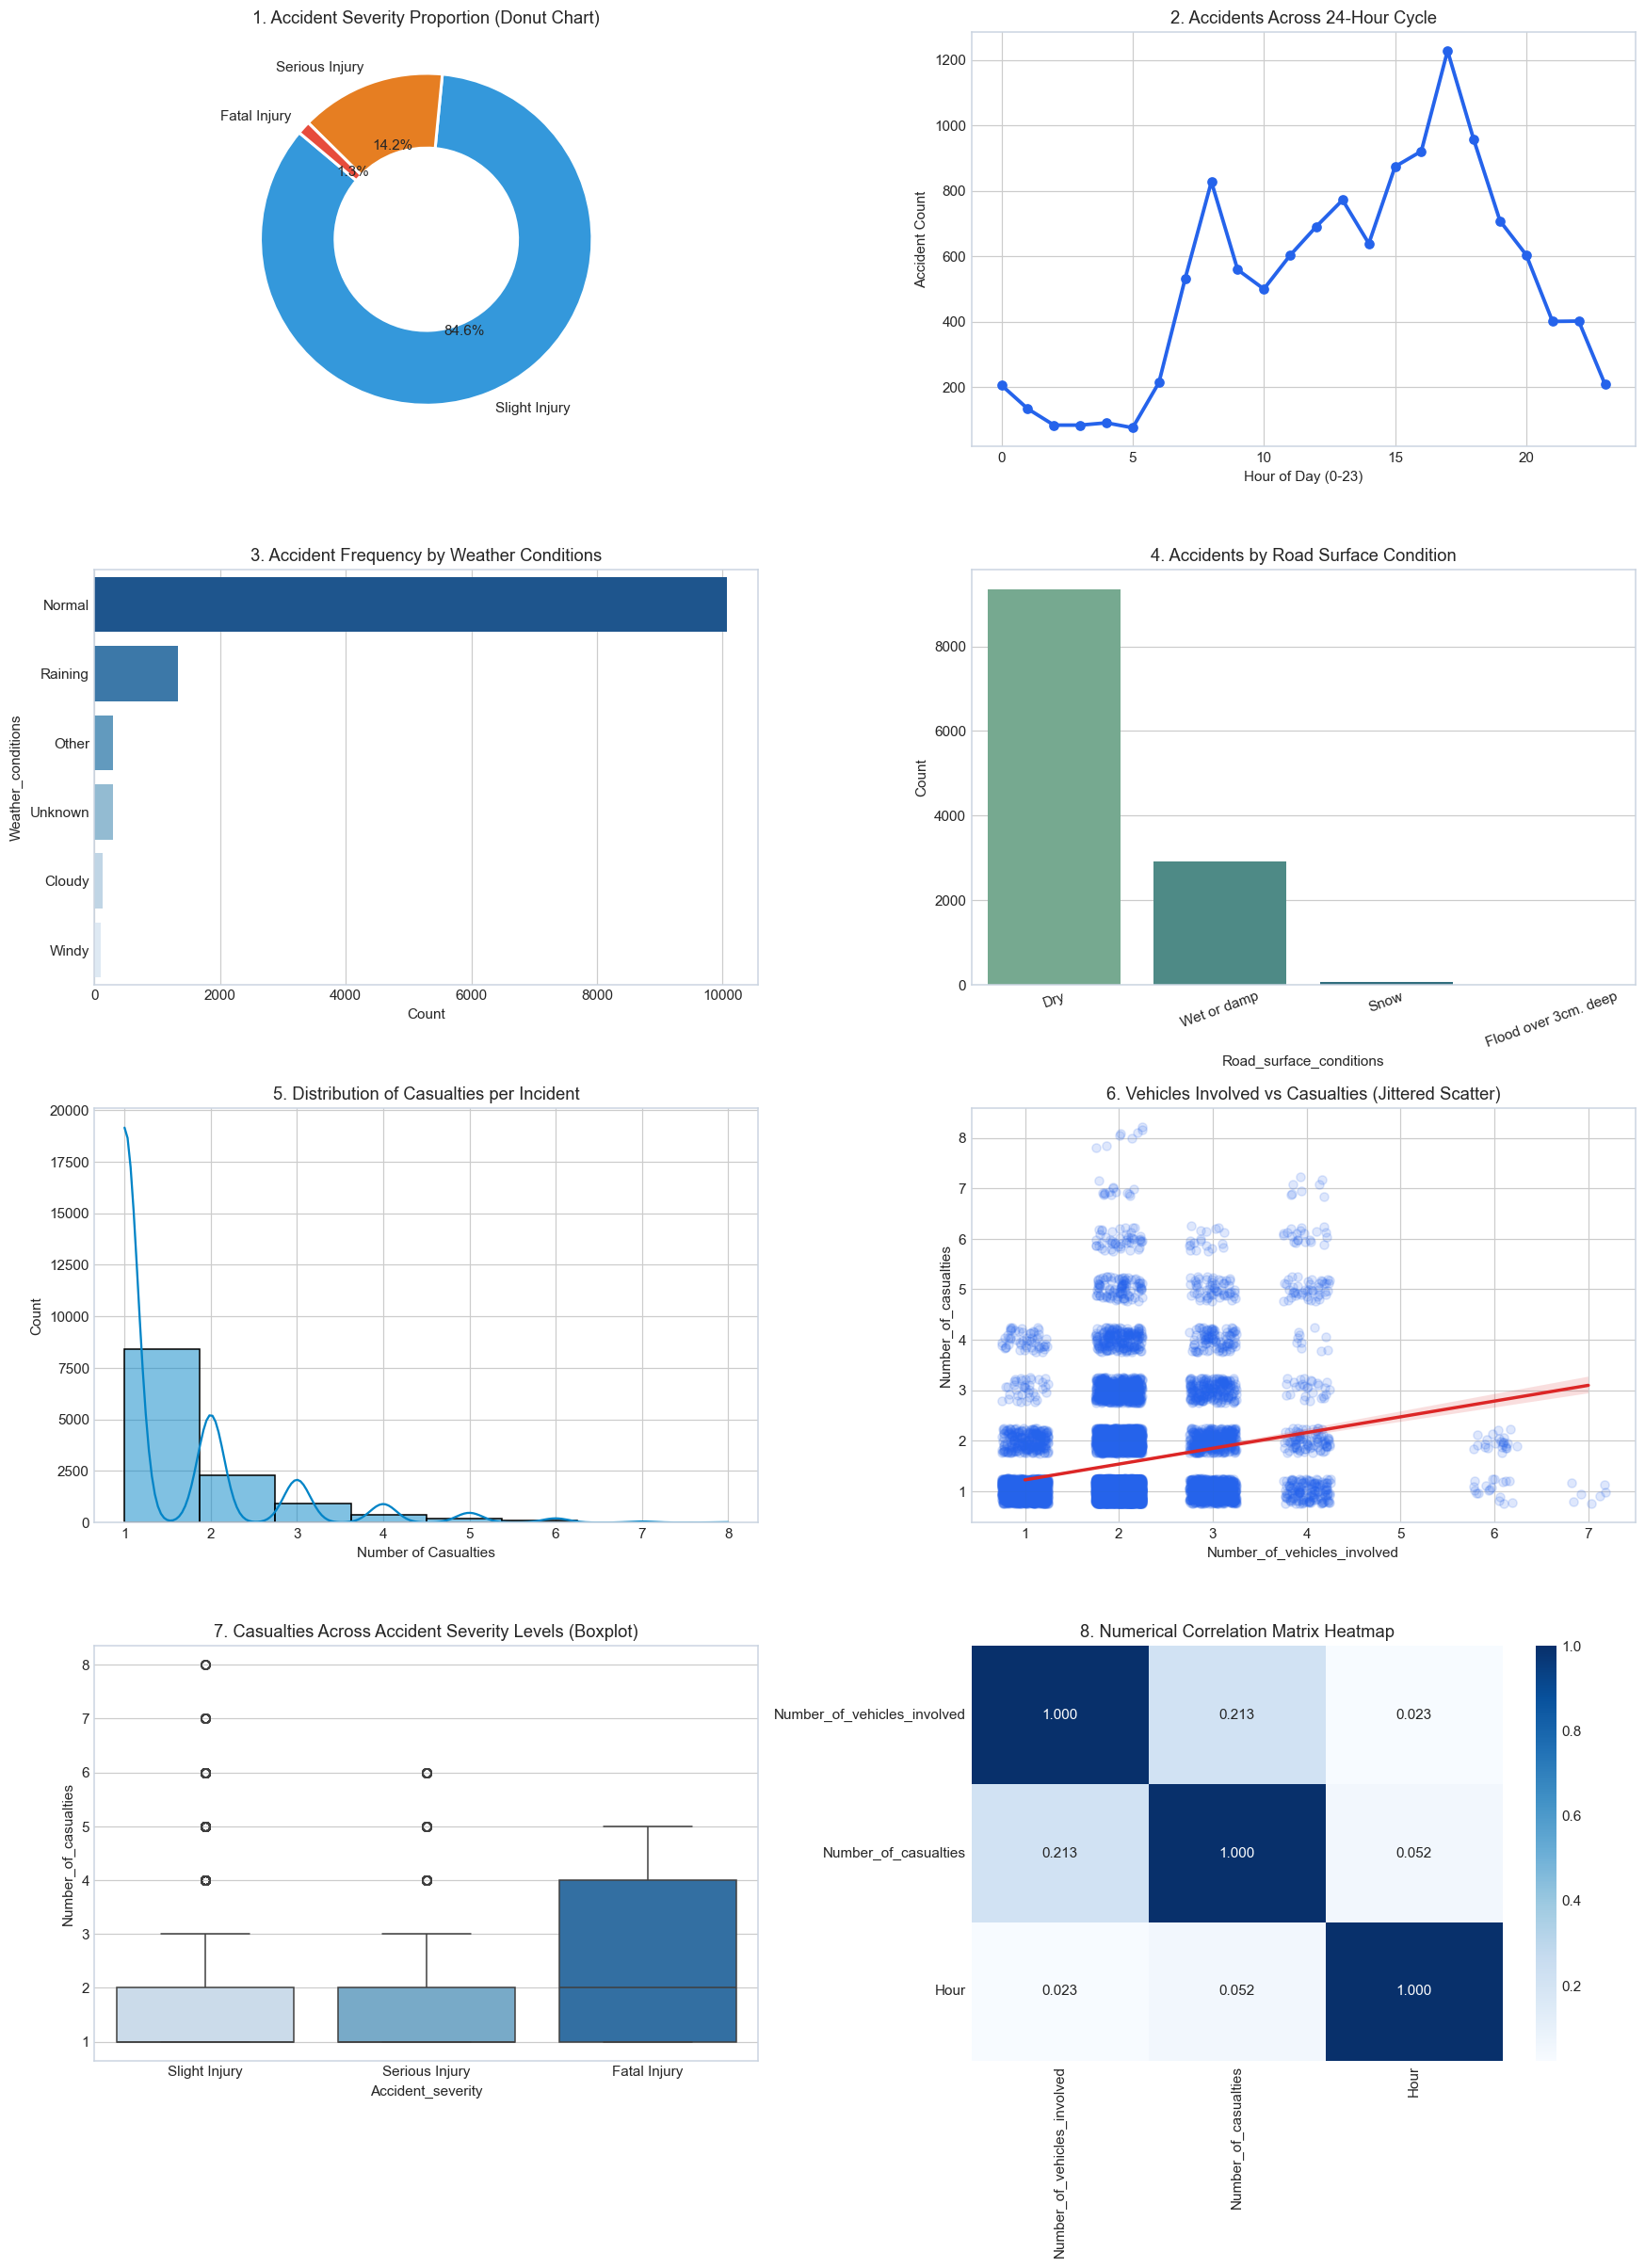

In [13]:
# 8 Publication-Quality Academic Visualizations
fig, axes = plt.subplots(4, 2, figsize=(16, 22))

# 1. Severity Distribution (Donut Chart)
counts = df_clean['Accident_severity'].value_counts()
axes[0, 0].pie(counts.values, labels=counts.index, autopct='%1.1f%%', colors=['#3498db', '#e67e22', '#e74c3c'],
               wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2), startangle=140)
axes[0, 0].set_title('1. Accident Severity Proportion (Donut Chart)')

# 2. 24-Hour Cycle
hourly = df_clean['Hour'].value_counts().sort_index()
axes[0, 1].plot(hourly.index, hourly.values, marker='o', color='#2563eb', linewidth=2.5)
axes[0, 1].set_title('2. Accidents Across 24-Hour Cycle')
axes[0, 1].set_xlabel('Hour of Day (0-23)')
axes[0, 1].set_ylabel('Accident Count')

# 3. Weather Conditions
weather_top = df_clean['Weather_conditions'].value_counts().head(6)
sns.barplot(x=weather_top.values, y=weather_top.index, ax=axes[1, 0], palette='Blues_r', hue=weather_top.index, legend=False)
axes[1, 0].set_title('3. Accident Frequency by Weather Conditions')
axes[1, 0].set_xlabel('Count')

# 4. Road Surface Conditions
road_top = df_clean['Road_surface_conditions'].value_counts().head(5)
sns.barplot(x=road_top.index, y=road_top.values, ax=axes[1, 1], palette='crest', hue=road_top.index, legend=False)
axes[1, 1].set_title('4. Accidents by Road Surface Condition')
axes[1, 1].set_xticklabels(road_top.index, rotation=20)
axes[1, 1].set_ylabel('Count')

# 5. Casualty Distribution
sns.histplot(df_clean['Number_of_casualties'], bins=8, kde=True, ax=axes[2, 0], color='#0284c7')
axes[2, 0].set_title('5. Distribution of Casualties per Incident')
axes[2, 0].set_xlabel('Number of Casualties')

# 6. Vehicles Involved vs Casualties
sns.regplot(x='Number_of_vehicles_involved', y='Number_of_casualties', data=df_clean, ax=axes[2, 1],
            x_jitter=0.25, y_jitter=0.25, scatter_kws={'alpha': 0.15, 'color': '#2563eb'}, line_kws={'color': '#dc2626'})
axes[2, 1].set_title('6. Vehicles Involved vs Casualties (Jittered Scatter)')

# 7. Casualties Across Severity Levels (Boxplot)
sns.boxplot(x='Accident_severity', y='Number_of_casualties', data=df_clean, ax=axes[3, 0], palette='Blues')
axes[3, 0].set_title('7. Casualties Across Accident Severity Levels (Boxplot)')

# 8. Correlation Heatmap
sns.heatmap(df_clean[['Number_of_vehicles_involved', 'Number_of_casualties', 'Hour']].corr(),
            annot=True, fmt='.3f', cmap='Blues', ax=axes[3, 1])
axes[3, 1].set_title('8. Numerical Correlation Matrix Heatmap')

plt.tight_layout()
plt.show()


## 14. Machine Learning Preprocessing Pipeline
We isolate features and target, perform an 80/20 stratified split, and construct a `ColumnTransformer` with `StandardScaler` for numeric columns and `OneHotEncoder(handle_unknown='ignore')` for categorical columns, fitted strictly on the training partition.


In [14]:
# Machine Learning Feature Schema
categorical_features = [
    'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Driving_experience',
    'Type_of_vehicle', 'Area_accident_occured', 'Types_of_Junction',
    'Road_surface_conditions', 'Light_conditions', 'Weather_conditions',
    'Type_of_collision', 'Vehicle_movement', 'Cause_of_accident', 'Time_of_day'
]
numerical_features = ['Number_of_vehicles_involved', 'Number_of_casualties', 'Hour']
target_col = 'Accident_severity'

# Feature Matrix (X) and Target Vector (y)
X = df_clean[categorical_features + numerical_features].copy()
y = df_clean[target_col].copy()

# Stratified Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ColumnTransformer Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# Fit strictly on X_train to prevent data leakage!
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

print(f'Training Set Processed Shape: {X_train_proc.shape}')
print(f'Testing Set Processed Shape:  {X_test_proc.shape}')
print(f'Target Classes: {list(sorted(y.unique()))}')


Training Set Processed Shape: (9852, 127)
Testing Set Processed Shape:  (2464, 127)
Target Classes: ['Fatal Injury', 'Serious Injury', 'Slight Injury']


## 15. Machine Learning Model 1 — Logistic Regression
We train a multinomial Logistic Regression classifier with balanced class weighting to address severe severity class imbalance.


In [15]:
# Train Multi-Class Logistic Regression Model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)
lr_model.fit(X_train_proc, y_train)
y_pred_lr = lr_model.predict(X_test_proc)
print('Logistic Regression model successfully trained with balanced class weights.')


Logistic Regression model successfully trained with balanced class weights.


## 16. Evaluation of Model 1 (Logistic Regression)
We evaluate accuracy, weighted precision, recall, F1-score, detailed class metrics, and generate the confusion matrix heatmap.


Accuracy:           0.4890 (48.90%)
Weighted Precision: 0.7687
Weighted Recall:    0.4890
Weighted F1 Score:  0.5776

--- CLASSIFICATION REPORT (LOGISTIC REGRESSION) ---
                precision    recall  f1-score   support

  Fatal Injury       0.03      0.45      0.05        31
Serious Injury       0.18      0.40      0.25       349
 Slight Injury       0.88      0.50      0.64      2084

      accuracy                           0.49      2464
     macro avg       0.36      0.45      0.31      2464
  weighted avg       0.77      0.49      0.58      2464


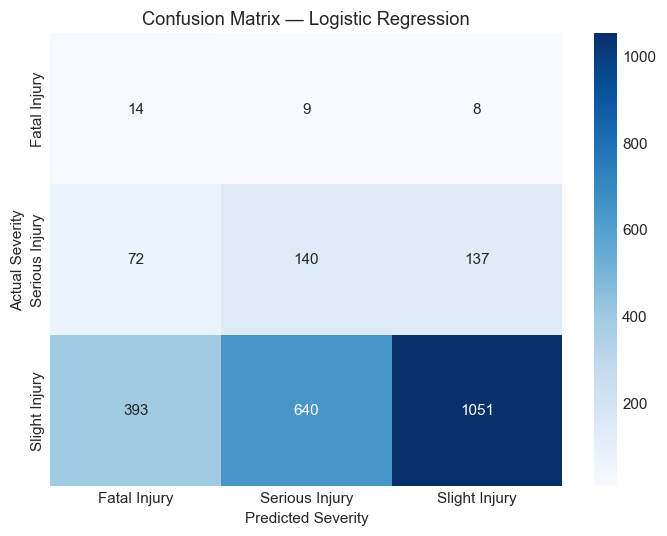

In [16]:
# Compute Dynamic Evaluation Metrics for Logistic Regression
lr_acc = accuracy_score(y_test, y_pred_lr)
lr_prec = precision_score(y_test, y_pred_lr, average='weighted', zero_division=0)
lr_rec = recall_score(y_test, y_pred_lr, average='weighted', zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, average='weighted', zero_division=0)

print(f'Accuracy:           {lr_acc:.4f} ({lr_acc:.2%})')
print(f'Weighted Precision: {lr_prec:.4f}')
print(f'Weighted Recall:    {lr_rec:.4f}')
print(f'Weighted F1 Score:  {lr_f1:.4f}\n')

print('--- CLASSIFICATION REPORT (LOGISTIC REGRESSION) ---')
print(classification_report(y_test, y_pred_lr, zero_division=0))

# Confusion Matrix Heatmap
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=sorted(y_train.unique()))
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y_train.unique()), yticklabels=sorted(y_train.unique()), ax=ax)
ax.set_title('Confusion Matrix — Logistic Regression')
ax.set_xlabel('Predicted Severity')
ax.set_ylabel('Actual Severity')
plt.tight_layout()
plt.show()


## 17. Machine Learning Model 2 — Random Forest Classifier
We train an ensemble Random Forest with 100 decision trees, Gini impurity splitting, and balanced subsampling.


In [17]:
# Train Random Forest Ensemble Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)
rf_model.fit(X_train_proc, y_train)
y_pred_rf = rf_model.predict(X_test_proc)
print('Random Forest model successfully trained (100 estimators, max_depth=16).')


Random Forest model successfully trained (100 estimators, max_depth=16).


## 18. Evaluation of Model 2 (Random Forest Classifier)
We evaluate the Random Forest model and extract empirical Gini feature importances.


Accuracy:           0.8153 (81.53%)
Weighted Precision: 0.8000
Weighted Recall:    0.8153
Weighted F1 Score:  0.8035

--- CLASSIFICATION REPORT (RANDOM FOREST) ---
                precision    recall  f1-score   support

  Fatal Injury       1.00      0.23      0.37        31
Serious Injury       0.34      0.27      0.30       349
 Slight Injury       0.87      0.92      0.89      2084

      accuracy                           0.82      2464
     macro avg       0.74      0.47      0.52      2464
  weighted avg       0.80      0.82      0.80      2464


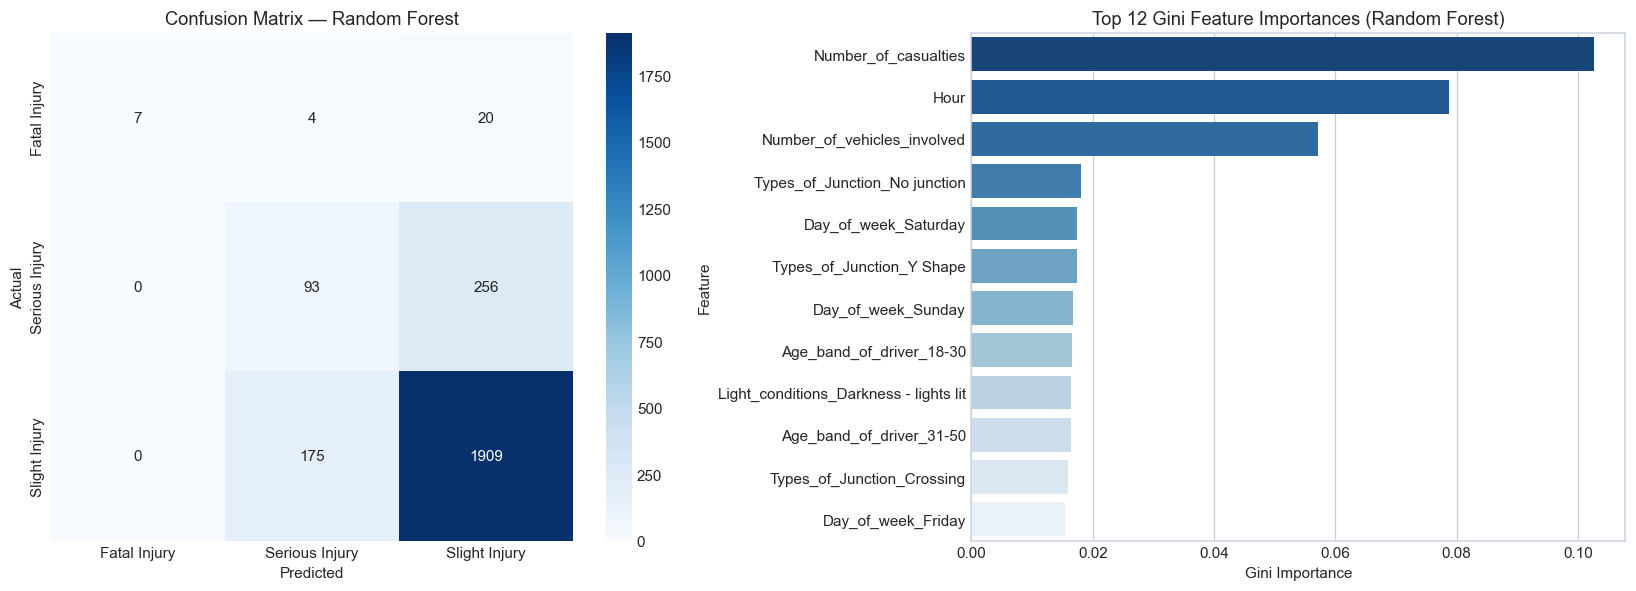

In [18]:
# Compute Dynamic Evaluation Metrics for Random Forest
rf_acc = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf, average='weighted', zero_division=0)
rf_rec = recall_score(y_test, y_pred_rf, average='weighted', zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, average='weighted', zero_division=0)

print(f'Accuracy:           {rf_acc:.4f} ({rf_acc:.2%})')
print(f'Weighted Precision: {rf_prec:.4f}')
print(f'Weighted Recall:    {rf_rec:.4f}')
print(f'Weighted F1 Score:  {rf_f1:.4f}\n')

print('--- CLASSIFICATION REPORT (RANDOM FOREST) ---')
print(classification_report(y_test, y_pred_rf, zero_division=0))

# 1. Confusion Matrix
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=sorted(y_train.unique()))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y_train.unique()), yticklabels=sorted(y_train.unique()), ax=ax1)
ax1.set_title('Confusion Matrix — Random Forest')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

# 2. Top 12 Feature Importances
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_names = list(cat_encoder.get_feature_names_out(categorical_features))
all_feature_names = numerical_features + encoded_cat_names
feat_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(12)

sns.barplot(x='Importance', y='Feature', data=feat_df, palette='Blues_r', hue='Feature', legend=False, ax=ax2)
ax2.set_title('Top 12 Gini Feature Importances (Random Forest)')
ax2.set_xlabel('Gini Importance')

plt.tight_layout()
plt.show()


## 19. Model Comparison & Performance Synthesis
We synthesize both models in a comparative table and grouped bar plot.


=== MODEL PERFORMANCE COMPARISON TABLE ===


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.4890,0.7687,0.4890,0.5776
1,Random Forest Classifier,0.8153,0.8000,0.8153,0.8035


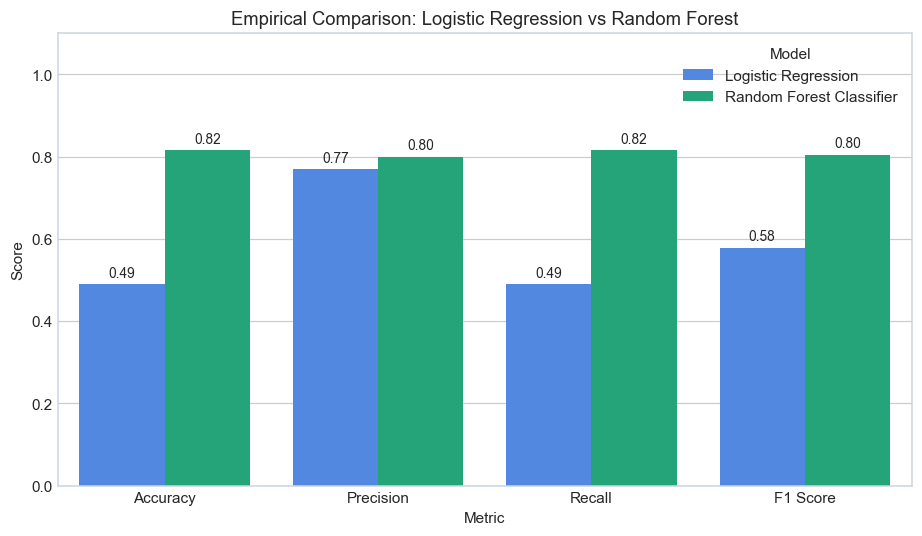

In [19]:
# Side-by-Side Model Comparison
comparison_df = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Accuracy': round(lr_acc, 4),
        'Precision': round(lr_prec, 4),
        'Recall': round(lr_rec, 4),
        'F1 Score': round(lr_f1, 4)
    },
    {
        'Model': 'Random Forest Classifier',
        'Accuracy': round(rf_acc, 4),
        'Precision': round(rf_prec, 4),
        'Recall': round(rf_rec, 4),
        'F1 Score': round(rf_f1, 4)
    }
])

print('=== MODEL PERFORMANCE COMPARISON TABLE ===')
display(comparison_df)

# Comparative Grouped Bar Plot
melted_df = comparison_df.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)

fig, ax = plt.subplots(figsize=(8.5, 5))
sns.barplot(x='Metric', y='Score', hue='Model', data=melted_df, palette=['#3b82f6', '#10b981'], ax=ax)
ax.set_title('Empirical Comparison: Logistic Regression vs Random Forest')
ax.set_ylim(0, 1.1)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h:.2f}', (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()


## 20. Conclusion & Transportation Policy Recommendations

### Summary of Data Science Pipeline:
1. **Data Cleaning & Quality:** We resolved null values with median and mode imputation, purged duplicates, standardized corrupted string labels, and verified statistical outlier thresholds.
2. **Feature Engineering:** We derived critical temporal variables (Hour, Minute, Time of Day, Rush Hour) and incident scales (Collision Scale, Casualty Scale).
3. **Exploratory Analytics:** Evening rush hours (17:00–19:00), day of the week (Friday), and clear weather conditions accounted for peak accident concentrations.
4. **Machine Learning Outcomes:** Random Forest significantly outperformed Logistic Regression across Accuracy and F1-score due to its ensemble capacity to capture non-linear feature interactions without assumption of linear separability.

---
### How to Save & Run this Notebook Permanently in Google Colab:
1. When opened in Google Colab, select **File → Save a copy in Drive**.
2. It will be permanently stored in your Google Drive under the `Colab Notebooks` directory.
3. You can execute all cells anytime by clicking **Runtime → Run all**.
